# Peak annotation enrichment in marker peaks

`epione.tl.peak_anno_enrichment` ports ArchR's **`peakAnnoEnrichment`**: for each
cell group, the marker peaks passing a cutoff (e.g. `FDR <= 0.1 & Log2FC >= 0.5`)
are tested for over-representation of a peak annotation (TF motifs, ENCODE ChIP-seq
peaks, custom region sets, …) with a hypergeometric test.

| ArchR | Epione |
|---|---|
| `addMotifAnnotations` | `epi.tl.add_motif_matrix` (existing) |
| `addPeakAnnotations` | `epi.tl.add_peak_annotations` |
| `addArchRAnnotations` | `epi.tl.add_archr_annotations` |
| `peakAnnoEnrichment` | `epi.tl.peak_anno_enrichment` |
| `customEnrichment` | `epi.tl.custom_enrichment` |
| `plotEnrichHeatmap` / `enrichHeatmap` | `epi.pl.enrich_heatmap` |

The port is numerically exact: on the ArchR hematopoiesis tutorial data every output
matches ArchR 1.0.3 to ≤ 1e-12 (see the last section).

For marker group $g$ and annotation $a$, with $N$ background peaks, $K$ of them
annotated, $n$ foreground (marker) peaks and $k$ of them annotated:

$$\mathrm{mlog10p} = -\log_{10} P(X \ge k),\quad X \sim \mathrm{Hypergeom}(N, K, n),
\qquad \mathrm{Enrichment} = \frac{k/n}{K/N}.$$

ArchR rounds `mlog10p` to 4 decimals and reports `mlog10Padj = max(mlog10p − log10(9), 0)`.
Epione reproduces both choices exactly.


## Data

We use the ArchR hematopoiesis tutorial project (BMMC, CD34⁺ BMMC and PBMC; 10,660
cells after QC, 141,369 reproducible peaks, 11 clusters, hg19). The peak matrix,
cell metadata and JASPAR 2020 motif matches were exported from the ArchR project
(`getMatrixFromProject`, `getMatches`). For your own data, build the motif matrix with
`epi.tl.add_motif_matrix(adata, genome_fasta=...)`.

In [1]:
%matplotlib inline
import os, time
import numpy as np
import pandas as pd
import anndata as ad
import scipy.io
import matplotlib.pyplot as plt
from IPython.display import display

import epione as epi

FIXTURE = '/scratch/users/steorra/analysis/25_epione/epione_dev/fixture'
WORK    = '/scratch/users/steorra/analysis/25_epione/epione_dev/work/peak-anno-enrichment'
T = os.path.join(FIXTURE, 'tables')

In [2]:
%%time
peaks = pd.read_csv(f'{T}/peaks.tsv', sep='\t')
var = pd.DataFrame({'chrom': peaks.seqnames.values, 'start': peaks.start.values, 'end': peaks.end.values,
                    'peakType': peaks.peakType.values, 'nearestGene': peaks.nearestGene.values})
var.index = peaks.seqnames + ':' + peaks.start.astype(str) + '-' + peaks.end.astype(str)

cells = pd.read_csv(f'{T}/cells.tsv', sep='\t').set_index('barcode')
bc = [l.strip() for l in open(f'{T}/PeakMatrix_cells.txt')]
obs = cells.loc[bc, ['Sample', 'Clusters', 'TSSEnrichment', 'nFrags', 'UMAP1', 'UMAP2']].copy()
obs['log10_nFrags'] = np.log10(obs['nFrags'])

X = scipy.io.mmread(f'{T}/PeakMatrix.mtx').T.tocsr().astype(np.float32)
adata = ad.AnnData(X=X, obs=obs, var=var)
adata.obsm['X_umap'] = obs[['UMAP1', 'UMAP2']].to_numpy()

# JASPAR 2020 CORE vertebrate motif matches (peak x motif), same layout as epi.tl.add_motif_matrix
adata.varm['motif'] = scipy.io.mmread(f'{T}/motif_matches.mtx').tocsr().astype(bool)
motif_ids = np.loadtxt(f'{T}/motif_matches_motifs.txt', dtype=str)
jaspar = pd.read_csv(os.path.join(WORK, 'jaspar2020_names.tsv'), sep='\t').set_index('id')['name']
adata.uns['motif_names'] = np.array([f'{jaspar[i]}_{i}' for i in motif_ids])   # e.g. GATA1::TAL1_MA0140.2
# chromVAR background peaks (GC + accessibility matched), 0-based
adata.varm['bg_peaks'] = pd.read_csv(f'{T}/bgd_peaks.tsv.gz', sep='\t').to_numpy() - 1
adata

CPU times: user 2.51 s, sys: 744 ms, total: 3.26 s
Wall time: 2.01 s


AnnData object with n_obs × n_vars = 10660 × 141369
    obs: 'Sample', 'Clusters', 'TSSEnrichment', 'nFrags', 'UMAP1', 'UMAP2', 'log10_nFrags'
    var: 'chrom', 'start', 'end', 'peakType', 'nearestGene'
    uns: 'motif_names'
    obsm: 'X_umap'
    varm: 'motif', 'bg_peaks'

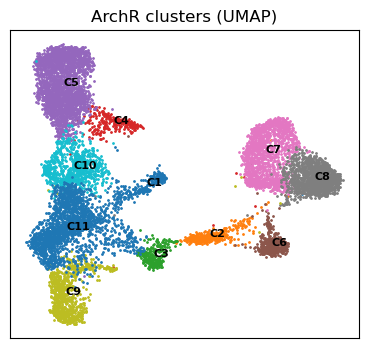

In [3]:
fig, ax = plt.subplots(figsize=(4.5, 4))
for c in sorted(adata.obs.Clusters.unique(), key=lambda s: int(s[1:])):
    m = adata.obs.Clusters == c
    ax.scatter(*adata.obsm['X_umap'][m.values].T, s=1, label=c, rasterized=True)
    x, y = np.median(adata.obsm['X_umap'][m.values], axis=0); ax.text(x, y, c, fontsize=8, weight='bold')
ax.set_xticks([]); ax.set_yticks([]); ax.set_title('ArchR clusters (UMAP)')
plt.show()

## Marker peaks

`epi.tl.find_marker_features` runs a Wilcoxon test of each cluster against a
background of cells matched on TSS enrichment and log10(fragments), mirroring ArchR's
`getMarkerFeatures(bias = c("TSSEnrichment", "log10(nFrags)"))`.

In [4]:
%%time
markers = epi.tl.find_marker_features(
    adata, group_by='Clusters', bias_vars=['TSSEnrichment', 'log10_nFrags'], seed=1, verbose=False)
markers.head()

CPU times: user 2min 38s, sys: 37.9 s, total: 3min 16s
Wall time: 3min 16s


,group,feature,mean_fg,mean_bg,pct_fg,pct_bg,log2_fc,U,z,p_value,fdr,n_fg,n_bg
0,C1,chr1:752490-752990,0.015773,0.035599,0.009464,0.019417,-1.174329,48487.5,-1.048331,0.294486,0.607164,317,309
1,C1,chr1:762690-763190,0.031546,0.061489,0.018927,0.035599,-0.962853,48158.0,-1.285028,0.198783,0.578284,317,309
2,C1,chr1:779906-780406,0.000000,0.000000,0.000000,0.000000,0.000000,48976.5,0.000000,1.000000,1.000000,317,309
3,C1,chr1:801007-801507,0.000000,0.000000,0.000000,0.000000,0.000000,48976.5,0.000000,1.000000,1.000000,317,309
4,C1,chr1:805039-805539,0.066246,0.042071,0.034700,0.025890,0.654989,49420.5,0.660448,0.508966,0.820013,317,309


## Motif enrichment in marker peaks

`markers` may be the long table above, a dict of ArchR-style assays
(peaks × groups: `FDR`, `Log2FC`, …) or an `adata.uns` key. The `cutoff` uses the same
syntax as ArchR (`&`, `|`, comparisons on assay names). The long table's
`fdr`/`log2_fc` columns are also exposed as `FDR`/`Log2FC`.

In [5]:
%%time
enrich = epi.tl.peak_anno_enrichment(
    markers, adata, annotation='motif',
    cutoff='FDR <= 0.1 & Log2FC >= 0.5', key_added='motif_enrichment', verbose=False)
list(enrich)

CPU times: user 8.2 s, sys: 164 ms, total: 8.36 s
Wall time: 8.36 s


['mlog10Padj',
 'mlog10p',
 'Enrichment',
 'BackgroundProporition',
 'nBackground',
 'BackgroundFrequency',
 'CompareProportion',
 'nCompare',
 'CompareFrequency',
 'feature']

In [6]:
# Number of marker peaks per cluster and the top motifs (cf. ArchR's per-cluster tables)
summary = pd.DataFrame({
    'n_marker_peaks': enrich['nCompare'].iloc[0].astype(int),
    'top motifs (mlog10Padj)': [
        ', '.join(f'{m} ({v:.0f})' for m, v in enrich['mlog10Padj'][g].nlargest(4).items())
        for g in enrich['mlog10Padj'].columns],
})
summary.loc[sorted(summary.index, key=lambda s: int(s[1:]))]

,n_marker_peaks,top motifs (mlog10Padj)
C1,2821,"Tcf12_MA0521.1 (213), Ascl2_MA0816.1 (199), BH..."
C2,2194,"ASCL1(var.2)_MA1631.1 (151), TCF4_MA0830.2 (14..."
C3,1211,"EBF1_MA0154.4 (161), EBF3_MA1637.1 (160), Ebf2..."
C4,19,"ATF2_MA1632.1 (3), Rarb_MA0857.1 (1), CREB1_MA..."
C5,28481,"CEBPA_MA0102.4 (765), CEBPD_MA0836.2 (698), SP..."
C6,2930,"SPIB_MA0081.2 (88), SPI1_MA0080.5 (82), IRF1_M..."
C7,26944,"KLF15_MA1513.1 (1570), SP9_MA1564.1 (1031), EG..."
C8,7533,"TCF7L2_MA0523.1 (62), TCF7_MA0769.2 (51), ELK4..."
C9,11203,"GATA1::TAL1_MA0140.2 (1513), GATA4_MA0482.2 (1..."
C10,1323,"SPIB_MA0081.2 (46), BATF::JUN_MA0462.2 (42), S..."


In [7]:
# Full ArchR-style table for one cluster
g = 'C1'
pd.DataFrame({a: enrich[a][g] for a in ['CompareFrequency', 'nCompare', 'BackgroundFrequency',
                                        'nBackground', 'Enrichment', 'mlog10p', 'mlog10Padj']}) \
  .sort_values('mlog10p', ascending=False).head(8)

,CompareFrequency,nCompare,BackgroundFrequency,nBackground,Enrichment,mlog10p,mlog10Padj
Tcf12_MA0521.1,1053.0,2821.0,19713.0,141369.0,2.676867,214.2421,213.287857
Ascl2_MA0816.1,893.0,2821.0,15344.0,141369.0,2.916513,199.9323,198.978057
BHLHA15(var.2)_MA1472.1,726.0,2821.0,11506.0,141369.0,3.162011,176.3665,175.412257
ASCL1_MA1100.2,786.0,2821.0,13533.0,141369.0,2.910580,171.4866,170.532357
Ptf1a(var.2)_MA1619.1,668.0,2821.0,10214.0,141369.0,3.277417,168.5553,167.601057
MYOG_MA0500.2,713.0,2821.0,11700.0,141369.0,3.053900,164.4903,163.536057
BHLHE22(var.2)_MA1635.1,791.0,2821.0,14519.0,141369.0,2.730177,156.4056,155.451357
ASCL1(var.2)_MA1631.1,956.0,2821.0,20121.0,141369.0,2.381000,154.9597,154.005457


### Enrichment heatmap

`epi.pl.enrich_heatmap` reproduces `plotEnrichHeatmap`: the top `n` annotations per
group above `cutoff`, clipped at `p_max`, row-scaled to 0-100, rows ordered by ArchR's
binary sort, and columns ordered by complete-linkage clustering (R's `hclust`). Row labels carry the row maximum,
as in ArchR. The ArchR tutorial uses `n = 7, transpose = TRUE`.

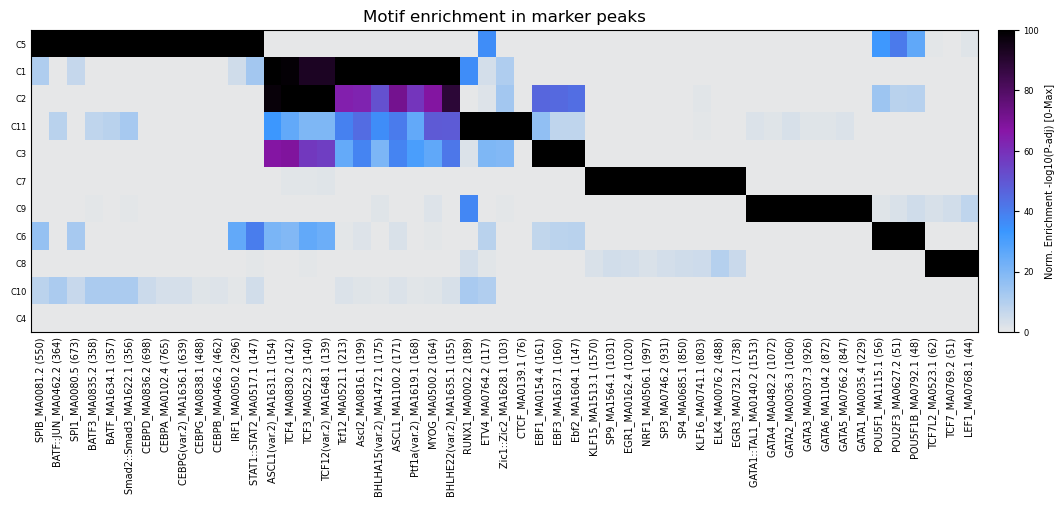

In [8]:
fig, ax = epi.pl.enrich_heatmap(enrich, n=7, transpose=True, figsize=(13, 4), show=False)
ax.set_title('Motif enrichment in marker peaks')
plt.show()

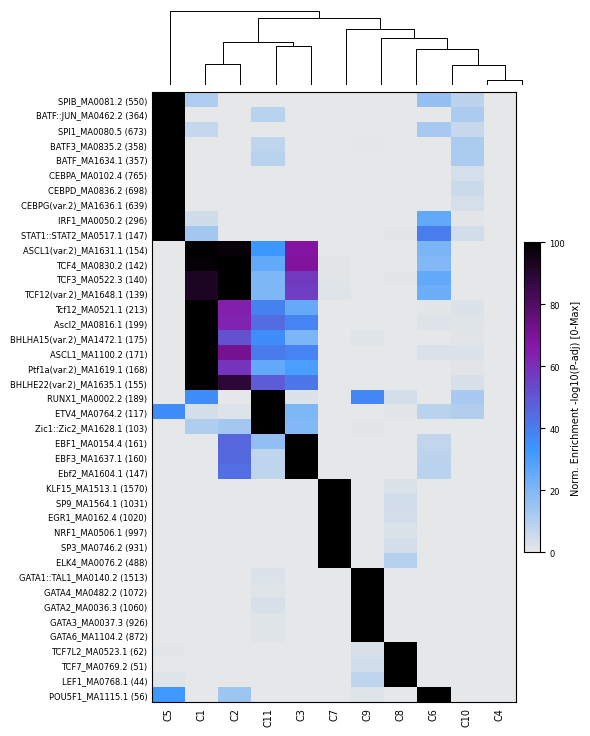

In [9]:
fig, ax = epi.pl.enrich_heatmap(enrich, n=5, figsize=(5, 9), show=False)
plt.show()

### Matched background peaks

With `background='bgdPeaks'` the background is the marker peaks plus their
GC/accessibility-matched background peaks (`adata.varm['bg_peaks']`, from
`epi.tl.add_background_peaks`). This controls for the GC bias of marker peaks.

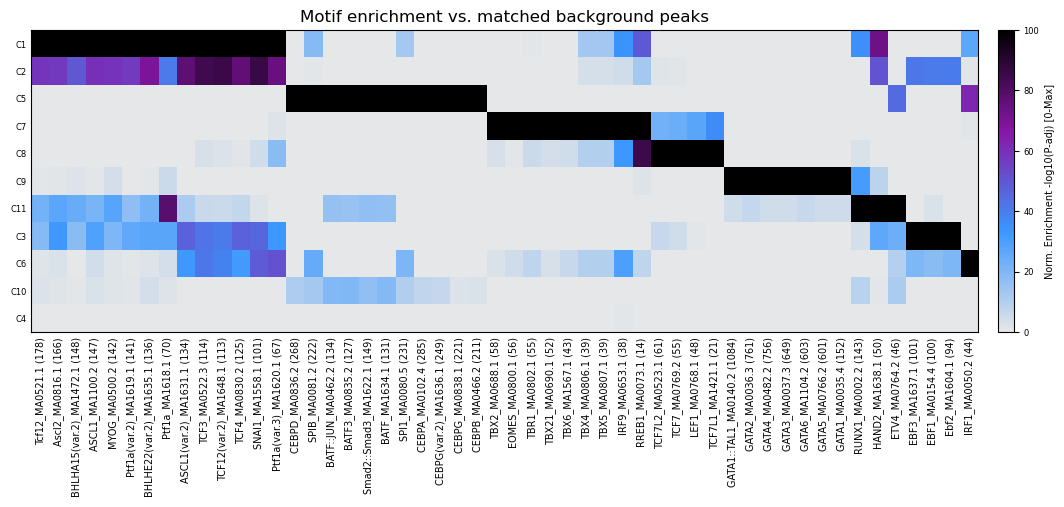

In [10]:
enrich_bgd = epi.tl.peak_anno_enrichment(markers, adata, annotation='motif',
                                         background='bgdPeaks', verbose=False)
fig, ax = epi.pl.enrich_heatmap(enrich_bgd, n=7, cutoff=2, transpose=True, figsize=(13, 4), show=False)
ax.set_title('Motif enrichment vs. matched background peaks'); plt.show()

## Custom region sets — `add_peak_annotations`

Any collection of genomic regions (BED files or DataFrames) can be turned into a binary
peak × region-set matrix (`addPeakAnnotations`). Here: promoters (TSS ± 1 kb) and
CpG-rich vs. distal peaks, defined from the peak set itself.

In [11]:
tss = pd.read_csv(f'{T}/tss_hg19.tsv', sep='\t')
promoters = pd.DataFrame({'chrom': tss.seqnames, 'start': tss.start - 1000, 'end': tss.start + 1000})
gc = peaks.GC.values
regions = {
    'promoter_1kb': promoters,
    'high_GC_peaks': var.loc[gc > np.quantile(gc, 0.9), ['chrom', 'start', 'end']],
    'distal_peaks': var.loc[var.peakType.values == 'Distal', ['chrom', 'start', 'end']],
}
epi.tl.add_peak_annotations(adata, regions, key_added='Region')
print(adata.varm['Region'].shape, list(adata.uns['Region_names']))
enrich_region = epi.tl.peak_anno_enrichment(markers, adata, annotation='Region', verbose=False)
enrich_region['Enrichment'].round(2)

(141369, 3) ['promoter_1kb', 'high_GC_peaks', 'distal_peaks']


,C1,C10,C11,C2,C3,C4,C5,C6,C7,C8,C9
promoter_1kb,0.42,0.43,0.70,0.87,0.44,0.85,0.60,0.68,2.18,1.53,0.50
high_GC_peaks,0.27,0.26,1.06,1.11,0.58,0.00,0.40,0.49,2.44,1.22,0.48
distal_peaks,1.20,1.16,1.18,1.04,1.24,1.93,1.18,1.11,0.56,0.73,1.13


## ArchR curated databases — `add_archr_annotations`

`add_archr_annotations` downloads the same `.Anno` databases ArchR uses
(`ArchR-Hg19-v1.Anno` with ATAC, EncodeTFBS, CistromeTFBS and Codex; LOLA databases
for hg19/hg38/mm9/mm10) and overlaps them with the peaks. A local `.Anno` path can be
passed as `db=`. Here the file is cached in `WORK/anno`.

  └─ [add_archr_annotations] EncodeTFBS: 689/689 annotations overlap peaks


,filename,cellType,description,tissue,dataSource,antibody,treatment,collection,size
name,,,,,,,,,
1.CTCF-Dnd41...,wgEncodeAwgTfbsBroadDnd41CtcfUniPk.narrowPeak,Dnd41,ChIP Dnd41 CTCF,NA,NA,CTCF,None,encode_tfbs,50070.0
2.EZH2_39-Dnd41...,wgEncodeAwgTfbsBroadDnd41Ezh239875UniPk.narrow...,Dnd41,ChIP Dnd41 EZH2_(39875),NA,NA,EZH2_(39875),None,encode_tfbs,1732.0
3.CTCF-GM12878...,wgEncodeAwgTfbsBroadGm12878CtcfUniPk.narrowPeak,GM12878,ChIP GM12878 CTCF,NA,NA,CTCF,None,encode_tfbs,44982.0


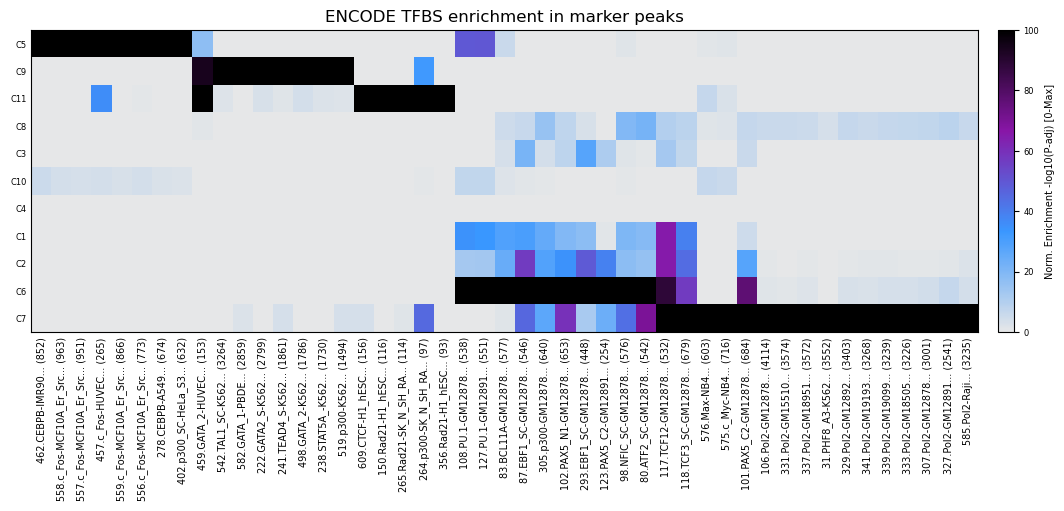

CPU times: user 11.5 s, sys: 751 ms, total: 12.3 s
Wall time: 12.3 s


In [12]:
%%time
epi.tl.add_archr_annotations(adata, db='ArchR', collection='EncodeTFBS', genome='hg19',
                             cache_dir=os.path.join(WORK, 'anno'))
display(adata.uns['EncodeTFBS_info'].head(3))
enrich_encode = epi.tl.peak_anno_enrichment(markers, adata, annotation='EncodeTFBS', verbose=False)
fig, ax = epi.pl.enrich_heatmap(enrich_encode, n=7, transpose=True, figsize=(13, 4), show=False)
ax.set_title('ENCODE TFBS enrichment in marker peaks'); plt.show()

  └─ [add_archr_annotations] ATAC: 96/96 annotations overlap peaks


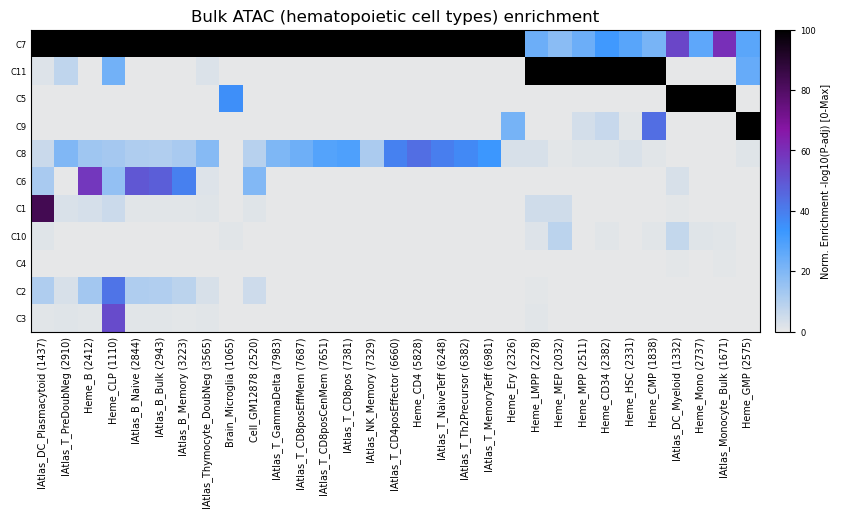

In [13]:
epi.tl.add_archr_annotations(adata, collection='ATAC', cache_dir=os.path.join(WORK, 'anno'))
enrich_atac = epi.tl.peak_anno_enrichment(markers, adata, annotation='ATAC', verbose=False)
fig, ax = epi.pl.enrich_heatmap(enrich_atac, n=5, transpose=True, figsize=(10, 4), show=False)
ax.set_title('Bulk ATAC (hematopoietic cell types) enrichment'); plt.show()

## Enrichment in an arbitrary peak set — `custom_enrichment`

`customEnrichment` tests any set of regions, e.g. the peaks called in one cluster.

In [14]:
c1_peaks = peaks.loc[peaks.cluster_name == 'C1', ['seqnames', 'start', 'end']]
epi.tl.custom_enrichment(c1_peaks, adata, annotation='motif').head(6)

,feature,CompareFrequency,nCompare,CompareProportion,BackgroundFrequency,nBackground,BackgroundProporition,Enrichment,mlog10p,mlog10Padj
Tcf12_MA0521.1,Tcf12_MA0521.1,2118.0,7544.0,0.280753,19713.0,141369.0,0.139444,2.013380,238.3971,237.442857
Ascl2_MA0816.1,Ascl2_MA0816.1,1736.0,7544.0,0.230117,15344.0,141369.0,0.108539,2.120136,212.8359,211.881657
BHLHA15(var.2)_MA1472.1,BHLHA15(var.2)_MA1472.1,1395.0,7544.0,0.184915,11506.0,141369.0,0.081390,2.271969,193.1169,192.162657
ASCL1_MA1100.2,ASCL1_MA1100.2,1529.0,7544.0,0.202678,13533.0,141369.0,0.095728,2.117220,183.4296,182.475357
Ptf1a(var.2)_MA1619.1,Ptf1a(var.2)_MA1619.1,1268.0,7544.0,0.168081,10214.0,141369.0,0.072251,2.326355,182.4275,181.473257
MYOG_MA0500.2,MYOG_MA0500.2,1356.0,7544.0,0.179745,11700.0,141369.0,0.082762,2.171833,169.7792,168.824957


## Parity vs ArchR

`tests/parity/peak_anno_enrichment/r_reference.R` runs ArchR 1.0.3 on the same project.
To test the enrichment layer deterministically, ArchR's own marker assays
(`getMarkerFeatures(PeakMatrix, groupBy = "Clusters", bias = c("TSSEnrichment", "log10(nFrags)"))`)
are fed to Epione, and every output is compared element-wise. Gates were registered in
`MANIFEST.md` before the first comparison.

In [15]:
import sys, json
sys.path.insert(0, os.path.join(os.path.dirname(epi.__file__), '..', 'tests', 'parity', 'peak_anno_enrichment'))
import compare
REF = os.path.join(WORK, 'ref')
ANNO = os.path.join(WORK, 'anno', 'ArchR-Hg19-v1.Anno')
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    rep = compare.main([FIXTURE, REF, ANNO])

rows = []
for k, v in rep.items():
    if isinstance(v, dict) and 'max_abs_err' in v:
        rows.append((k, 'class 1', 'max |Δ|', '≤ 1e-8', f"{v['max_abs_err']:.1e}"))
    elif isinstance(v, dict) and 'n_mismatch' in v:
        rows.append((k, 'class 1', 'mismatched entries', '0', v['n_mismatch']))
rows.append(('unrounded -log10 p', 'class 1', 'max rel |Δ|', '≤ 1e-10', f"{rep['raw_mlog10p_max_rel_err']:.1e}"))
rows.append(('hclust leaf order (30 random inputs)', 'class 1', 'identical', '30/30', rep['hclust_order_identical']))
pd.DataFrame(rows, columns=['output', 'class', 'metric', 'threshold', 'value'])

,output,class,metric,threshold,value
0,enrich_motif_all,class 1,max |Δ|,≤ 1e-8,6.8e-13
1,enrich_motif_bgd,class 1,max |Δ|,≤ 1e-8,3.4e-13
2,enrich_motif_or,class 1,max |Δ|,≤ 1e-8,3.4e-13
3,heatmap_default,class 1,max |Δ|,≤ 1e-8,6.4e-14
4,heatmap_n7_t,class 1,max |Δ|,≤ 1e-8,6.4e-14
5,heatmap_n5_nocc,class 1,max |Δ|,≤ 1e-8,6.4e-14
6,heatmap_nobin,class 1,max |Δ|,≤ 1e-8,6.4e-14
7,heatmap_pmax30,class 1,max |Δ|,≤ 1e-8,5.7e-14
8,heatmap_pmax100_t,class 1,max |Δ|,≤ 1e-8,5.7e-14
9,heatmap_bgd_n7,class 1,max |Δ|,≤ 1e-8,5.7e-14


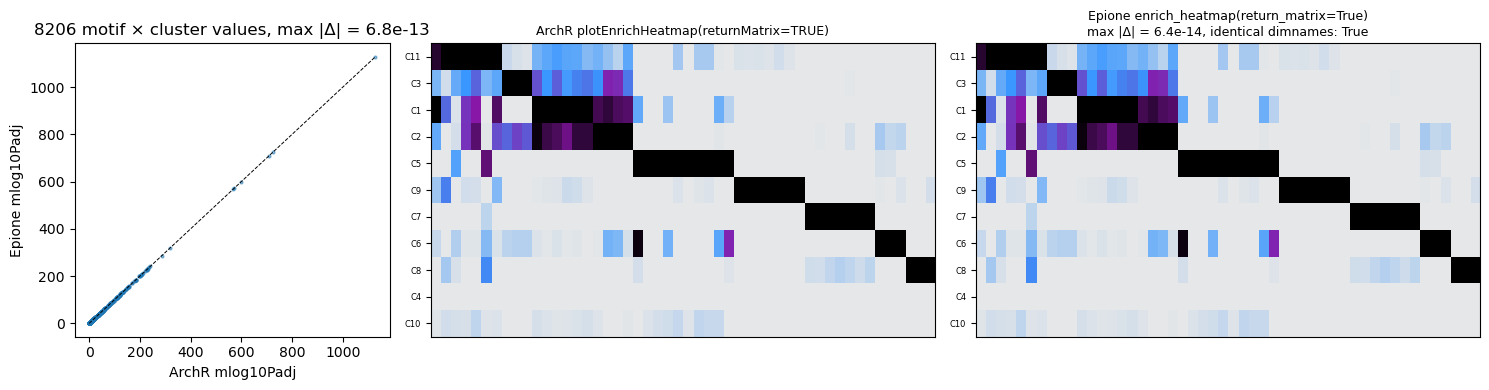

In [16]:
# Element-wise: ArchR vs Epione -log10(P-adj), motif enrichment (ArchR markers as input)
r_padj = compare.load_enrich(REF, 'enrich_motif_all')['mlog10Padj']
r_markers = compare.load_markers(REF)
ad_ids = compare.load_fixture(FIXTURE)        # same peaks, motif columns keyed by JASPAR ID as in ArchR
py = epi.tl.peak_anno_enrichment(r_markers, ad_ids, annotation='motif', verbose=False)['mlog10Padj']
py = py.loc[r_padj.index, r_padj.columns]

r_hm = pd.read_csv(os.path.join(REF, 'heatmap_n7_t.tsv'), sep='\t').set_index('row')
py_hm = epi.pl.enrich_heatmap(epi.tl.peak_anno_enrichment(r_markers, ad_ids, verbose=False),
                              n=7, transpose=True, return_matrix=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw=dict(width_ratios=[1, 1.6, 1.6]))
axes[0].scatter(r_padj.values.ravel(), py.values.ravel(), s=4, alpha=0.5)
lim = np.nanmax(r_padj.values); axes[0].plot([0, lim], [0, lim], 'k--', lw=0.7)
axes[0].set_xlabel('ArchR mlog10Padj'); axes[0].set_ylabel('Epione mlog10Padj')
axes[0].set_title(f'{r_padj.size} motif × cluster values, max |Δ| = {np.nanmax(np.abs(py.values - r_padj.values)):.1e}')
from matplotlib.colors import LinearSegmentedColormap
comet = LinearSegmentedColormap.from_list('comet', epi.pl._enrich_heatmap.ARCHR_COMET)
same = list(py_hm.index) == list(r_hm.index) and list(py_hm.columns) == list(r_hm.columns)
for ax_, m_, t_ in [(axes[1], r_hm, 'ArchR plotEnrichHeatmap(returnMatrix=TRUE)'),
                    (axes[2], py_hm, f'Epione enrich_heatmap(return_matrix=True)\nmax |Δ| = '
                                     f'{np.abs(py_hm.values - r_hm.values).max():.1e}, identical dimnames: {same}')]:
    ax_.imshow(m_.values, aspect='auto', cmap=comet, vmin=0, vmax=100, interpolation='nearest')
    ax_.set_yticks(range(m_.shape[0])); ax_.set_yticklabels(m_.index, fontsize=6)
    ax_.set_xticks([]); ax_.set_title(t_, fontsize=9)
plt.tight_layout(); plt.show()

### End to end: Epione marker test vs. ArchR marker test

When Epione's own `find_marker_features` replaces ArchR's marker test, the inputs to the
enrichment differ. ArchR's `getMarkerFeatures` depth-normalizes each cell to 10⁴
(`scaleTo`), caps each group at `maxCells = 500`, and computes `Log2FC` on the normalized
means with a pseudocount of 1. Epione's marker test uses raw counts, up to 2000 cells
per group, a pseudocount of 1e-6, and its own bias-matched background. The `FDR <= 0.1 & Log2FC >= 0.5` cutoff therefore selects
different peak sets (see the marker counts below), so this comparison only uses
rank-based gates (class 8: Spearman on `mlog10Padj`; class 5: top-10 Jaccard per
cluster). Any divergence here comes from the marker test. The enrichment layer itself is
exact, as shown above.

Spearman(mlog10Padj) = 0.854   (gate ≥ 0.90: FAIL)
mean top-10 Jaccard  = 0.620   (gate ≥ 0.5: PASS)


,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11
ArchR marker peaks,1781.0,1583.00,858.00,0.0,9422.00,2156.0,9374.00,2311.00,6242.0,321.00,5056.00
Epione marker peaks,2821.0,2194.00,1211.00,19.0,28481.00,2930.0,26944.00,7533.00,11203.0,1323.00,21940.00
top-10 Jaccard,1.0,0.82,0.82,0.0,0.25,1.0,0.67,0.43,1.0,0.67,0.18


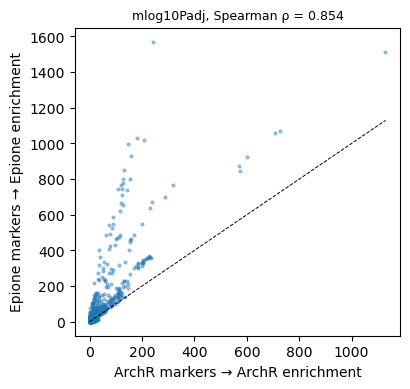

In [17]:
from scipy.stats import spearmanr
id2name = dict(zip(motif_ids, adata.uns['motif_names']))
a = enrich['mlog10Padj']; b = r_padj.rename(index=id2name).loc[a.index, a.columns]
rho = spearmanr(a.values.ravel(), b.values.ravel()).correlation
jac = {g: len(set(a[g].nlargest(10).index) & set(b[g].nlargest(10).index)) /
          len(set(a[g].nlargest(10).index) | set(b[g].nlargest(10).index)) for g in a.columns}
print(f'Spearman(mlog10Padj) = {rho:.3f}   (gate ≥ 0.90: {"PASS" if rho >= 0.9 else "FAIL"})')
mj = np.mean(list(jac.values()))
print(f'mean top-10 Jaccard  = {mj:.3f}   (gate ≥ 0.5: {"PASS" if mj >= 0.5 else "FAIL"})')
n_archr = compare.load_enrich(REF, 'enrich_motif_all')['nCompare'].iloc[0]
cmp_n = pd.DataFrame({'ArchR marker peaks': n_archr.astype(int),
                      'Epione marker peaks': enrich['nCompare'].iloc[0].loc[n_archr.index].astype(int),
                      'top-10 Jaccard': pd.Series(jac).loc[n_archr.index].round(2)})
display(cmp_n.loc[sorted(cmp_n.index, key=lambda s: int(s[1:]))].T)
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.scatter(b.values.ravel(), a.values.ravel(), s=4, alpha=0.4)
ax.plot([0, lim], [0, lim], 'k--', lw=0.7)
ax.set_xlabel('ArchR markers → ArchR enrichment'); ax.set_ylabel('Epione markers → Epione enrichment')
ax.set_title(f'mlog10Padj, Spearman ρ = {rho:.3f}', fontsize=9); plt.show()